# Exact three-dimensional view of complete input–output windows in R⁴

Here $m=p=1$ and $T_{\mathrm{ini}}=T_{\mathrm f}=1$, so $L=2$ and **every data point is the full vector**
$$w=\operatorname{col}(u_0,u_1,y_0,y_1)\in\mathbb R^4.$$

We select a two-parameter family of valid trajectories that lies in a three-dimensional linear subspace. Orthonormal coordinates of that subspace provide an exact, distance-preserving visualization of the full vectors. No input or output is omitted, and the displayed coordinates are not relabeled as a shorter trajectory.

This replaces the earlier three-selected-coordinate illustration. The figure retains the requested bright blue palette, true curved mesh, Times New Roman, single-column width, no title, and no highlighted point.

## 1. System, Hankel definition, and selected trajectories

Use the nonlinear scalar system
$$y_{k+1}=y_k^2+u_k.$$
For an input-output record, a column of $[H_2(u)^{\mathsf T},H_2(y)^{\mathsf T}]^{\mathsf T}$ is $(u_j,u_{j+1},y_j,y_{j+1})^{\mathsf T}$: two inputs and two outputs. More generally, $H_L(s)$ has columns $\operatorname{col}(s_j,\ldots,s_{j+L-1})$.

For this illustrative family, choose $y_0=x$ and $(u_0,u_1)=(a,-a)$, with $x\in[-1,1]$ and $a\in[-0.5,0.5]$. Simulation gives
$$y_1=x^2+a,\qquad y_2=(x^2+a)^2-a.$$
Thus each valid length-two trajectory is
$$w(a,x)=\begin{bmatrix}a&-a&x&x^2+a\end{bmatrix}^{\mathsf T}.$$
Both inputs are applied to the plant. The second input affects $y_2$, which is outside the stored length-two output block $(y_0,y_1)$, consistent with the strictly causal Hankel indexing convention.

The code constructs each vector as an actual column of the stacked depth-two Hankel matrices for its own experiment. Those columns are concatenated across independent experiments (a mosaic); no artificial transition is introduced between experiments. With the order $(u_0,u_1,y_0,y_1)$, the past is $(u_0,y_0)$ and the future is $(u_1,y_1)$. The common alternative order $(u_{\mathrm{ini}},y_{\mathrm{ini}},u_{\mathrm f},y_{\mathrm f})$ differs only by a row permutation.

In [1]:
from pathlib import Path
import importlib.util
import json
import numpy as np
from IPython.display import Image, display

PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents)
               if (p / "notebooks").is_dir() and (p / "src").is_dir())
FOLDER = PROJECT / "notebooks" / "motivation"
spec = importlib.util.spec_from_file_location("io_surface", FOLDER / "io_trajectory_surface.py")
io = importlib.util.module_from_spec(spec)
spec.loader.exec_module(io)
assert np.array_equal(io.block_hankel([1, 2, 3], 2), [[1, 2], [2, 3]])
example = io.trajectory_windows([0.6], [0.2])[0]
print("T_ini = T_f = 1; L = 2; ambient dimension = 4")
print("One full Hankel column [u0, u1, y0, y1]:", example)
print("Past [u0, y0]:", example[[0, 2]])
print("Future [u1, y1]:", example[[1, 3]])
assert np.allclose(example, [0.2, -0.2, 0.6, 0.56])

T_ini = T_f = 1; L = 2; ambient dimension = 4
One full Hankel column [u0, u1, y0, y1]: [ 0.2  -0.2   0.6   0.56]
Past [u0, y0]: [0.2 0.6]
Future [u1, y1]: [-0.2   0.56]


## 2. A curved surface inside a three-dimensional linear subspace

All selected vectors satisfy $u_0+u_1=0$, hence lie in
$$\mathcal S=\{w\in\mathbb R^4:u_0+u_1=0\},\qquad \dim\mathcal S=3.$$
This linear constraint is a restriction on the selected input records, not an identity of the unrestricted system. Within $\mathcal S$, the nonlinear dynamics impose $y_1=y_0^2+u_0$, defining a curved two-dimensional surface.

Choose the orthonormal basis matrix
$$Q=\begin{bmatrix}
1/\sqrt3&0&-1/\sqrt6\\
-1/\sqrt3&0&1/\sqrt6\\
0&1&0\\
1/\sqrt3&0&2/\sqrt6
\end{bmatrix},\qquad Q^{\mathsf T}Q=I_3.$$
For every selected full trajectory, let $z=Q^{\mathsf T}w$. Then
$$w=Qz,\qquad \|w_i-w_j\|_2=\|z_i-z_j\|_2.$$
This is an isometric change of coordinates of the full window vectors. It is not a truncated PCA approximation or a nonlinear decoder based on omitted samples.

Substitution gives
$$z_1=\sqrt3a+\frac{x^2}{\sqrt3},\qquad z_2=x,\qquad
z_3=\sqrt{\frac23}x^2,$$
so the exact displayed surface is a parabolic cylinder:
$$z_3=\sqrt{\frac23}\,z_2^2.$$
The original trajectory family is therefore curved even though its ambient visualization subspace is linear. The map $(a,x)\mapsto w$ has rank two everywhere because the first and third coordinates recover $a$ and $x$.

In [2]:
train, test, metrics = io.fit_diagnostics()
Q = io.Q
z = io.embedding(test)
assert np.allclose(Q.T @ Q, np.eye(3))
assert np.allclose(io.decode(z), test)
assert np.allclose(test[:, 0]+test[:, 1], 0)
assert np.allclose(test[:, 3], test[:, 2]**2+test[:, 0])
print("Full-data affine rank:", metrics["empirical_affine_span_rank"])
print("Maximum full-window reconstruction error:", metrics["max_full_window_reconstruction_error"])
print("Maximum checked squared-distance error:", metrics["max_pairwise_squared_distance_error"])
print("Maximum surface residual:", metrics["max_surface_residual"])

Full-data affine rank: 3
Maximum full-window reconstruction error: 4.440892098500626e-16
Maximum checked squared-distance error: 2.220446049250313e-15
Maximum surface residual: 2.220446049250313e-16


## 3. Publication figure: each dot is one complete four-dimensional window

The axes are the orthonormal trajectory coordinates $(z_1,z_2,z_3)$, not selected raw input/output entries. Each of the 529 plotted points is formed by applying $Q^{\mathsf T}$ to one full stacked Hankel column. The mesh is generated from additional valid windows along diagonal parameter sections; its curves lie exactly on the same surface. Mesh lines do not denote evolution in time.

Exports: [vector PDF](figures/io_trajectory_paper.pdf), [SVG](figures/io_trajectory_paper.svg), and [600 dpi PNG](figures/io_trajectory_paper.png). Width is 3.5 inches, with trimmed margins, Times New Roman, 8 pt ticks, and 9 pt labels.

Soft shading conveys surface orientation only; it does not encode an additional variable.

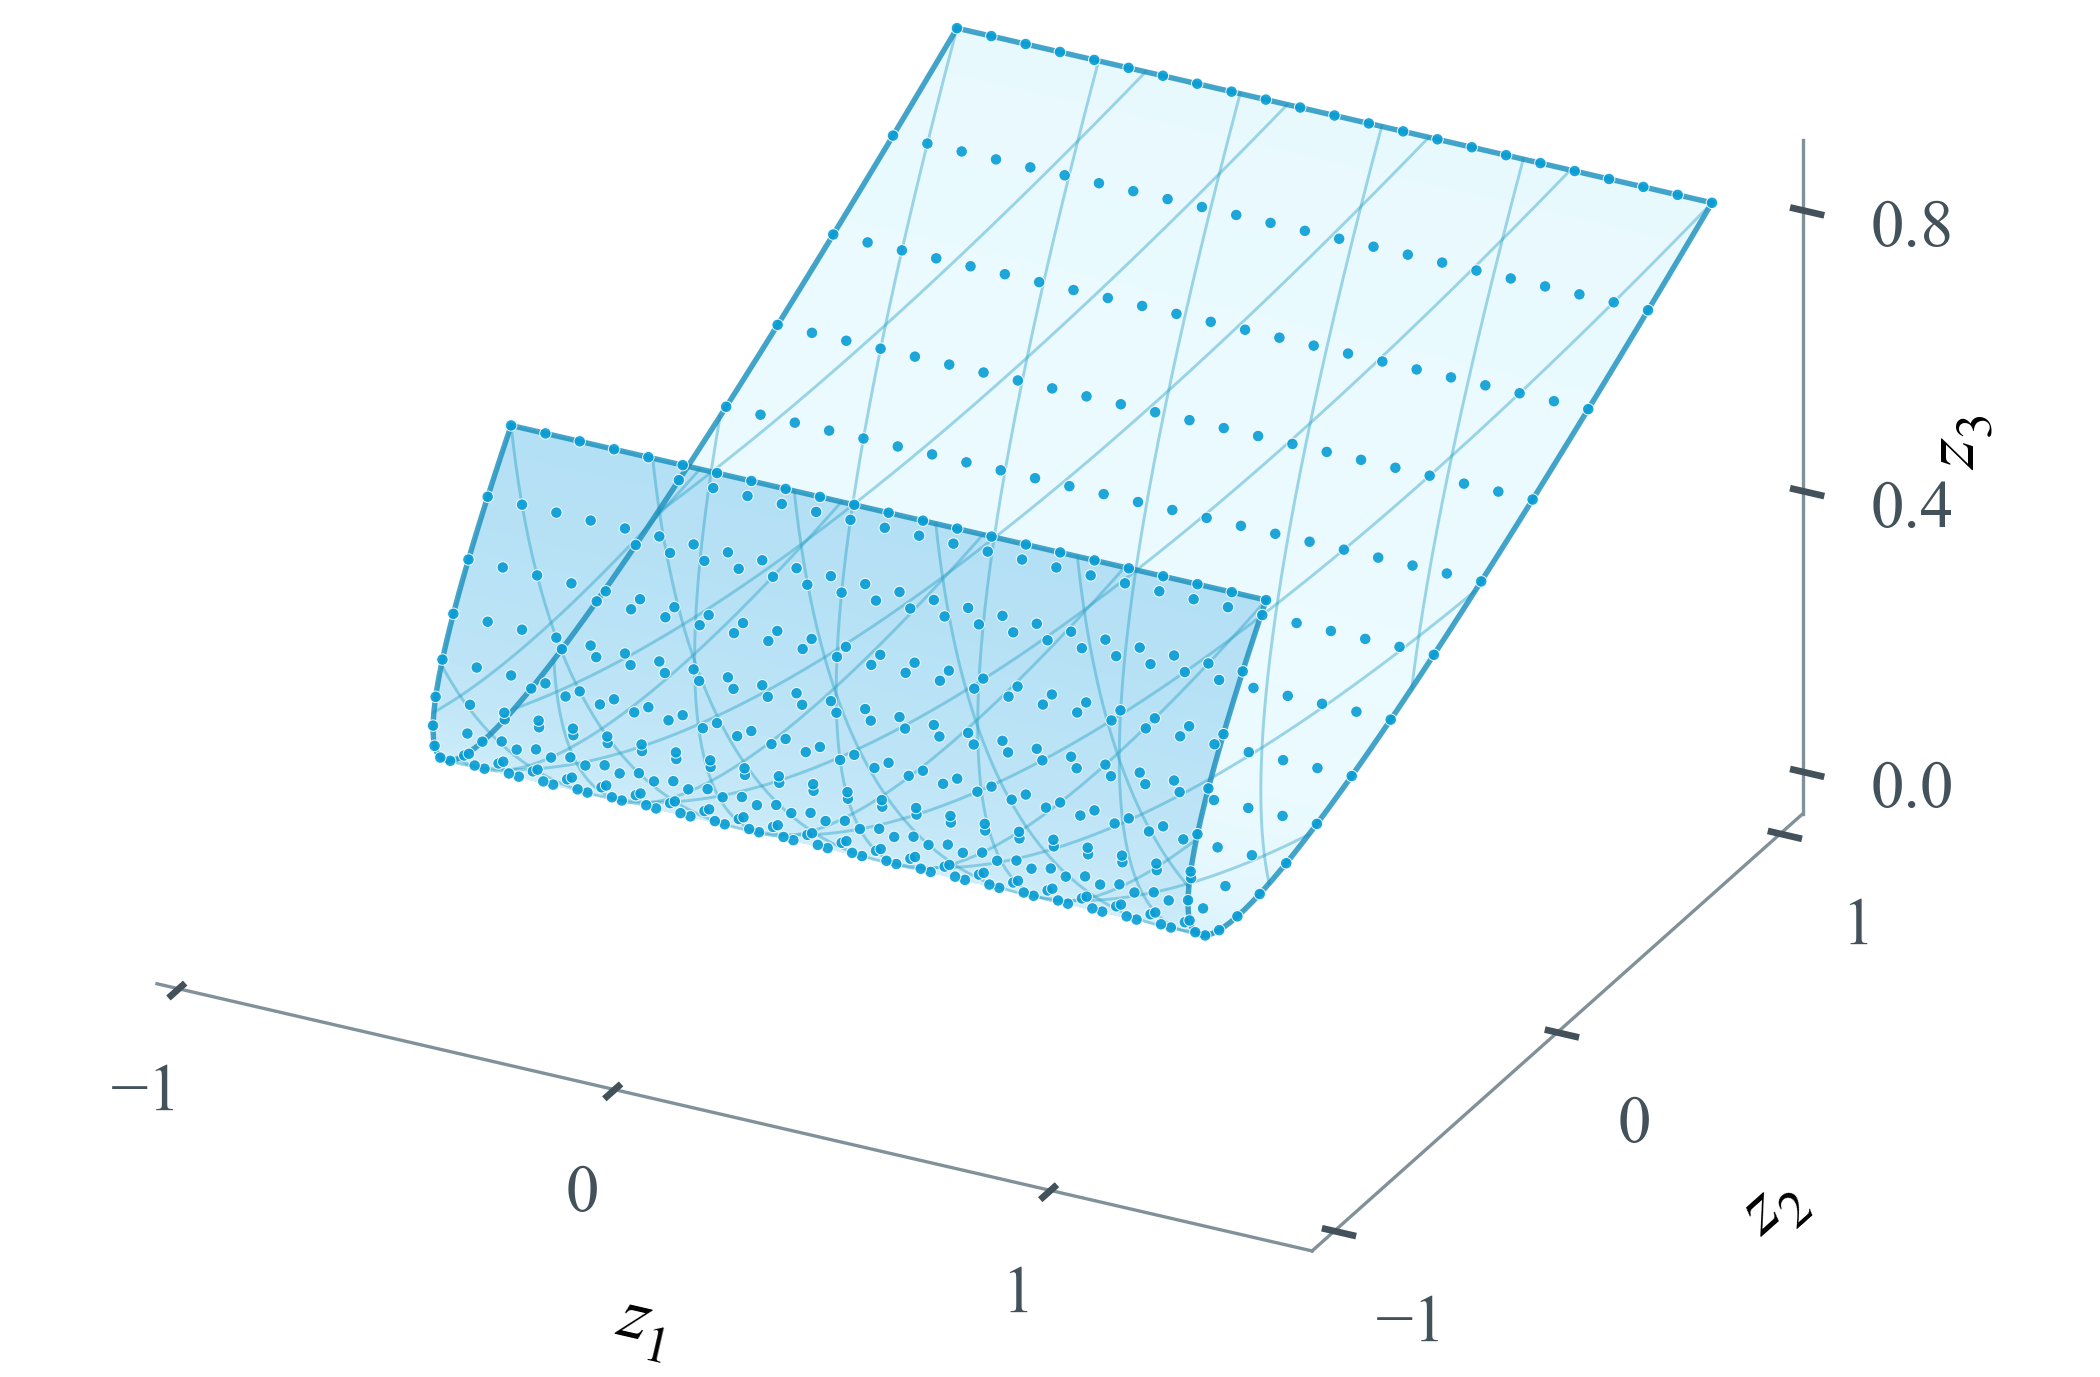

In [3]:
plotted = io.paper_figure()
assert plotted.shape == (529, 4)
assert np.allclose(io.decode(io.embedding(plotted)), plotted)
display(Image(filename=str(io.OUT / "io_trajectory_paper.png"), width=480))

## 4. Local affine approximations in the original trajectory space

Learn 16 groups with $K$-means on 1,200 full training vectors in $\mathbb R^4$. Fit a rank-two affine plane by centered SVD within each group, and compare with one global rank-two affine plane on 500 independently sampled test windows. All errors use the full two-input/two-output vectors. Because the visualization is isometric, this geometry is faithfully represented in the figure.

Test groups are assigned using complete test windows; this is an offline geometric reconstruction diagnostic, not causal chart selection, a prediction benchmark, or a closed-loop DeePC result. The collection of local planes has more total parameters. A linear-system control, $y_{k+1}=0.7y_k+u_k$, with the same input-pair restriction yields a rank-two linear window space, confirming that the nonlinear dynamics produce the curvature here.

The family is intentionally restricted. With arbitrary $(u_0,u_1,y_0)$, the full behavior has three free parameters in $\mathbb R^4$; we do not claim to exhaust that behavior or establish sufficient excitation for general DeePC.

In [4]:
print(f"Global rank-two RMS window error: {metrics['global_rank_two_window_rms']:.6f}")
print(f"Local rank-two RMS window error:  {metrics['local_rank_two_window_rms']:.6f}")
print("Linear-system control affine rank:", metrics["linear_system_control_affine_rank"])
(io.OUT / "io_trajectory_metrics.json").write_text(json.dumps(metrics, indent=2)+"\n")
np.savez_compressed(io.OUT / "io_trajectory_windows.npz", train=train, test=test,
                    plotted=plotted, basis=Q, T_ini=io.T_INI, T_f=io.T_F)
print("All Hankel, dynamics, reconstruction, distance, and geometry checks passed.")

Global rank-two RMS window error: 0.226819
Local rank-two RMS window error:  0.013118
Linear-system control affine rank: 2
All Hankel, dynamics, reconstruction, distance, and geometry checks passed.


## 5. Visualizing the learned behavioral atlas

Fix the same nonlinear plant and the same complete four-dimensional window family. K-means alone supplies a partition. To construct an illustrative affine atlas, fit a centered rank-two SVD basis to each group:
$$\mathcal A_j=c_j+\operatorname{im}B_j,\qquad B_j\in\mathbb R^{4\times2}.$$
Use eight charts for visibility. All clustering, centers, bases, and errors are computed in the full window space; $z=Q^{\mathsf T}w$ is the exact isometry used to draw both panels. The colored plane footprints are convex hulls of local projected data, not exact manifold boundaries. Colors are consistent between groups and planes.

**Interpretation:** the collection of local affine patches follows the curved trajectory family. K-means learns Euclidean neighborhoods rather than directly optimizing subspace error. The exact uncentered span of each group still has rank three and equals the common containing subspace: keeping that full span would not yield distinct local representations. Here the useful local geometry comes from affine centering and rank-two approximation.

This is a geometric atlas of the selected $u_1=-u_0$ family, not an implementation of closed-loop DeePC. Group assignment for the held-out diagnostic uses complete test windows, so it must not be interpreted as causal online selection. No transition graph is inferred from independent windows or overlapping plotted patches.


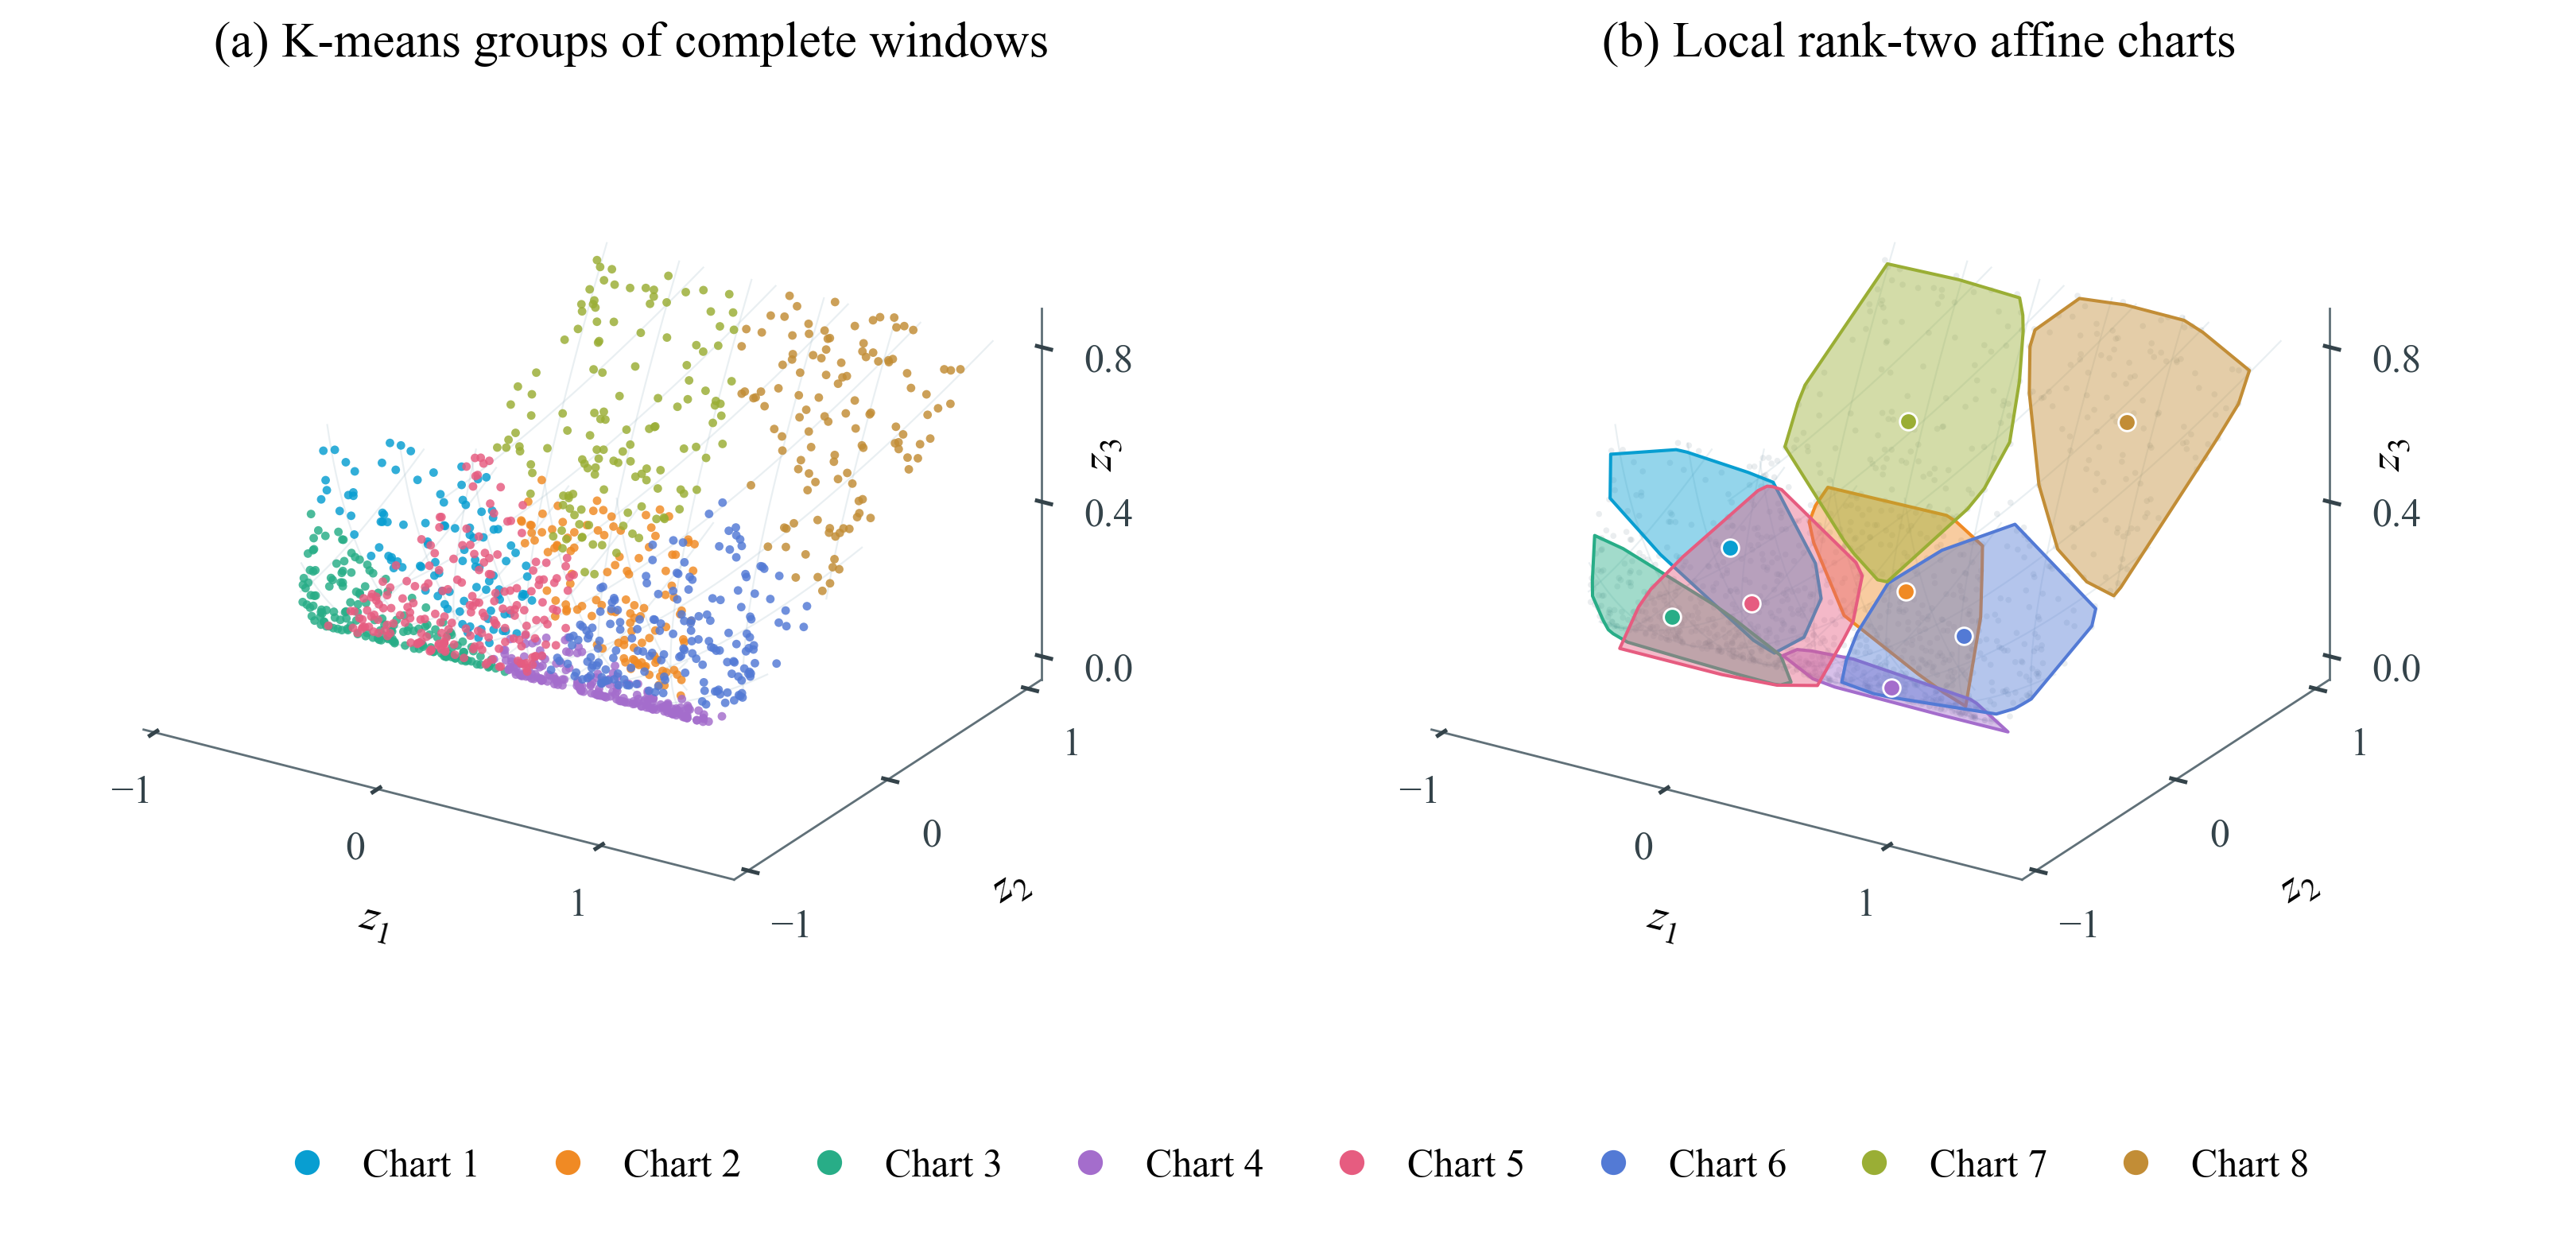

K    Held-out full-window RMS error
1    0.226819
4    0.047679
8    0.019160
16   0.013118
Training windows per group: [105, 114, 158, 195, 194, 178, 135, 121]
Exact uncentered ranks: [3, 3, 3, 3, 3, 3, 3, 3]


In [5]:
atlas_spec = importlib.util.spec_from_file_location("io_atlas", FOLDER / "io_behavioral_atlas.py")
atlas_module = importlib.util.module_from_spec(atlas_spec)
atlas_spec.loader.exec_module(atlas_module)
atlas_metrics = atlas_module.run()
display(Image(filename=str(io.OUT / "io_behavioral_atlas.png"), width=960))
print("K    Held-out full-window RMS error")
for row in atlas_metrics["sweep"]:
    print(f"{row['K']:<4} {row['test_window_rms']:.6f}")
print("Training windows per group:", [c["training_windows"] for c in atlas_metrics["charts"]])
print("Exact uncentered ranks:", [c["uncentered_full_rank"] for c in atlas_metrics["charts"]])


See [the atlas explanation and caption](io_behavioral_atlas.md), [overview PDF](figures/io_behavioral_atlas.pdf), and title-free single-column panels: [clusters](figures/io_atlas_clusters.pdf) and [affine charts](figures/io_atlas_charts.pdf). The exported NPZ contains all four-dimensional centers, bases, labels, training windows, and test windows.

## 6. Introduction text

The [introduction text and caption](io_trajectory_introduction.md) and [LaTeX wrapfigure snippet](io_trajectory_introduction.tex) now describe this complete-window construction. The old constant-input bilinear saddle and raw-coordinate labels have been superseded.